In [1]:
# Step 1: Read the local input file and configure shared tree settings.
from __future__ import annotations

import csv
import io
import urllib.request
from collections import Counter, defaultdict, deque
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
from matplotlib.patches import Circle
from matplotlib.textpath import TextPath


matplotlib.rcParams["svg.fonttype"] = "none"
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
matplotlib.rcParams["font.size"] = 21

ROOT = Path.cwd()
if not (ROOT / "ctann-v10.csv").exists():
    ROOT = ROOT / "notebook"

INPUT = ROOT / "CTann-Supertree-v10-official.csv"
OUTPUT_DIR = ROOT.parent / "vis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FOCAL_SOURCES = {"azimuth", "pan-human-azimuth"}
EXCLUDED_SOURCES = {"chenchen", "martin"}
AZIMUTH_NODE_FILL_COLOR = "#E31A1C"
PAN_HUMAN_AZIMUTH_NODE_FILL_COLOR = "#1E90FF"
OVERLAP_NODE_FILL_COLOR = "#7B2CBF"
OTHER_NODE_FILL_COLOR = "#8C8C8C"
LABEL_FONT_SIZE = 21
LABEL_MAX_CHARS = None  # Show complete node labels in this focused subtree.
COLUMNAR_CUBOIDAL_ROOT_ID = "CL:0000075"
DISPLAY_CELL_NODE_ID = "display:cell"
MATURE_ALPHA_BETA_T_CELL_ID = "CL:0000791"
HEMATOPOIETIC_CELL_ID = "CL:0000988"

rows = list(csv.DictReader(INPUT.open(newline="", encoding="utf-8-sig")))


# Official crosswalks define Azimuth and Pan-Human Azimuth membership.
# The hierarchy CSV remains the source of the asserted paths and labels.
OFFICIAL_CROSSWALK_URLS = {
    "azimuth": (
        "https://raw.githubusercontent.com/cns-iu/hra-ctann-supporting-information/"
        "main/supertree/data/azimuth-crosswalk.csv"
    ),
    "pan-human-azimuth": (
        "https://raw.githubusercontent.com/cns-iu/hra-ctann-supporting-information/"
        "main/supertree/data/pan-human-azimuth-crosswalk.csv"
    ),
}


def normalize_cl_id(value):
    """Normalize Cell Ontology IDs to the canonical CL:NNNNNNN form."""
    value = (value or "").strip()
    for prefix in (
        "http://purl.obolibrary.org/obo/",
        "https://purl.obolibrary.org/obo/",
    ):
        if value.startswith(prefix):
            value = value[len(prefix):]
    if value.upper().startswith("CL_"):
        value = "CL:" + value[3:]
    elif value.lower().startswith("cl:"):
        value = "CL:" + value[3:]
    return value


def load_official_crosswalk_ids(url):
    """Read CL_ID values after locating the real header past the preamble."""
    with urllib.request.urlopen(url, timeout=60) as response:
        text = response.read().decode("utf-8-sig")
    lines = text.splitlines()
    header_index = next(
        index for index, line in enumerate(lines) if line.startswith("Organ_Level")
    )
    crosswalk_rows = csv.DictReader(io.StringIO("\n".join(lines[header_index:])))
    ids = set()
    for row in crosswalk_rows:
        for value in row.get("CL_ID", "").split("/"):
            normalized = normalize_cl_id(value)
            if normalized:
                ids.add(normalized)
    return ids


OFFICIAL_SOURCE_IDS = {
    tool: load_official_crosswalk_ids(url)
    for tool, url in OFFICIAL_CROSSWALK_URLS.items()
}
print(
    "Official crosswalk vocabulary sizes:",
    {tool: len(ids) for tool, ids in OFFICIAL_SOURCE_IDS.items()},
)
for row in rows[:5]:
    print(row)


def get_tree_source_data(rows, *, max_as_level=None, root_id=None, expand_node_id=None):
    """Exclude selected sources and return path suffixes for one tree."""
    tree_rows = []
    source_counts = Counter()
    for row in rows:
        source_norm = row.get("CT/1 - Sources", "").strip().lower()
        if source_norm in EXCLUDED_SOURCES:
            continue

        full_path = []
        for level in range(1, 13):
            node_id = row.get(f"AS/{level}/ID", "").strip()
            node_label = row.get(f"AS/{level}/LABEL", "").strip()
            if node_id:
                full_path.append((node_id, node_label))

        if max_as_level:
            top_levels = full_path[:max_as_level]
            is_expanded_branch = expand_node_id and any(
                node_id == expand_node_id for node_id, _ in top_levels
            )
            path = full_path if is_expanded_branch else top_levels
        else:
            path = full_path

        if root_id:
            root_index = next(
                (index for index, (node_id, _) in enumerate(path) if node_id == root_id),
                None,
            )
            if root_index is None:
                continue
            path = path[root_index:]

        if not path:
            continue

        tree_rows.append((source_norm, path))
        source_counts[source_norm] += 1

    return tree_rows, source_counts


Official crosswalk vocabulary sizes: {'azimuth': 306, 'pan-human-azimuth': 241}
{'AS/1': 'cell', 'AS/1/ID': 'CL:0000000', 'AS/1/LABEL': 'cell', 'AS/2': 'endothelial cell', 'AS/2/ID': 'CL:0000115', 'AS/2/LABEL': 'endothelial cell', 'AS/3': 'endothelial cell of vascular tree', 'AS/3/ID': 'CL:0002139', 'AS/3/LABEL': 'endothelial cell of vascular tree', 'AS/4': 'blood vessel endothelial cell', 'AS/4/ID': 'CL:0000071', 'AS/4/LABEL': 'blood vessel endothelial cell', 'AS/5': '', 'AS/5/ID': '', 'AS/5/LABEL': '', 'AS/6': '', 'AS/6/ID': '', 'AS/6/LABEL': '', 'AS/7': '', 'AS/7/ID': '', 'AS/7/LABEL': '', 'AS/8': '', 'AS/8/ID': '', 'AS/8/LABEL': '', 'AS/9': '', 'AS/9/ID': '', 'AS/9/LABEL': '', 'AS/10': '', 'AS/10/ID': '', 'AS/10/LABEL': '', 'AS/11': '', 'AS/11/ID': '', 'AS/11/LABEL': '', 'AS/12': '', 'AS/12/ID': '', 'AS/12/LABEL': '', 'CT/1 - Sources': 'azimuth', 'BGene/1': 'sc_transcriptomics'}
{'AS/1': 'cell', 'AS/1/ID': 'CL:0000000', 'AS/1/LABEL': 'cell', 'AS/2': 'hematopoietic cell', 'AS/2/ID':

In [2]:
# Step 2: Keep the selected mature alpha-beta T cell branch and count cell's direct children.
mature_branch_rows, mature_branch_source_counts = get_tree_source_data(
    rows,
    root_id=MATURE_ALPHA_BETA_T_CELL_ID,
)
if not mature_branch_rows:
    raise ValueError("No mature alpha-beta T cell paths were found.")

direct_cell_child_ids = set()
for row in rows:
    source_norm = row.get("CT/1 - Sources", "").strip().lower()
    if source_norm in EXCLUDED_SOURCES:
        continue
    for level in range(1, 12):
        parent_id = row.get(f"AS/{level}/ID", "").strip()
        child_id = row.get(f"AS/{level + 1}/ID", "").strip()
        if parent_id == "CL:0000000" and child_id and child_id != parent_id:
            direct_cell_child_ids.add(child_id)
            break

CELL_CHILD_COUNT = len(direct_cell_child_ids)
tree1_rows = [
    (source_norm, [(DISPLAY_CELL_NODE_ID, "cell"), *path])
    for source_norm, path in mature_branch_rows
]

# Compute source membership using the published frontier rule.
# A tool is shown only when it contains this node and no more-specific
# descendant in the hierarchy.
full_tree_rows, _ = get_tree_source_data(rows)
full_tree_children = defaultdict(set)
full_tree_node_ids = set()
for _, path in full_tree_rows:
    for node_id, _ in path:
        full_tree_node_ids.add(node_id)
    for (parent_id, _), (child_id, _) in zip(path, path[1:]):
        if parent_id != child_id:
            full_tree_children[parent_id].add(child_id)


def official_tools_below(node_id):
    found = set()
    stack = list(full_tree_children.get(node_id, set()))
    while stack:
        child_id = stack.pop()
        found.update(
            tool for tool, crosswalk_ids in OFFICIAL_SOURCE_IDS.items()
            if child_id in crosswalk_ids
        )
        stack.extend(full_tree_children.get(child_id, set()))
    return found


official_node_sources = {
    node_id: {
        tool for tool, crosswalk_ids in OFFICIAL_SOURCE_IDS.items()
        if node_id in crosswalk_ids
    } - official_tools_below(node_id)
    for node_id in full_tree_node_ids
}

print("Official frontier nodes used in this tree, including leaves:", {
    tool: sum(tool in sources for sources in official_node_sources.values())
    for tool in OFFICIAL_CROSSWALK_URLS
})

print(f"Direct children of cell represented by the root: {CELL_CHILD_COUNT}")
print(f"Mature alpha-beta T cell branch paths: {len(mature_branch_rows)}")
print(dict(mature_branch_source_counts))


Official frontier nodes used in this tree, including leaves: {'azimuth': 217, 'pan-human-azimuth': 169}
Direct children of cell represented by the root: 10
Mature alpha-beta T cell branch paths: 85
{'azimuth': 19, 'celltypist': 17, 'deepcelltypes': 3, 'deepcelltypes-hubmap': 3, 'frmatch': 2, 'pan-human-azimuth': 12, 'popv': 14, 'ribca': 2, 'stellar': 2, 'vccf': 11}


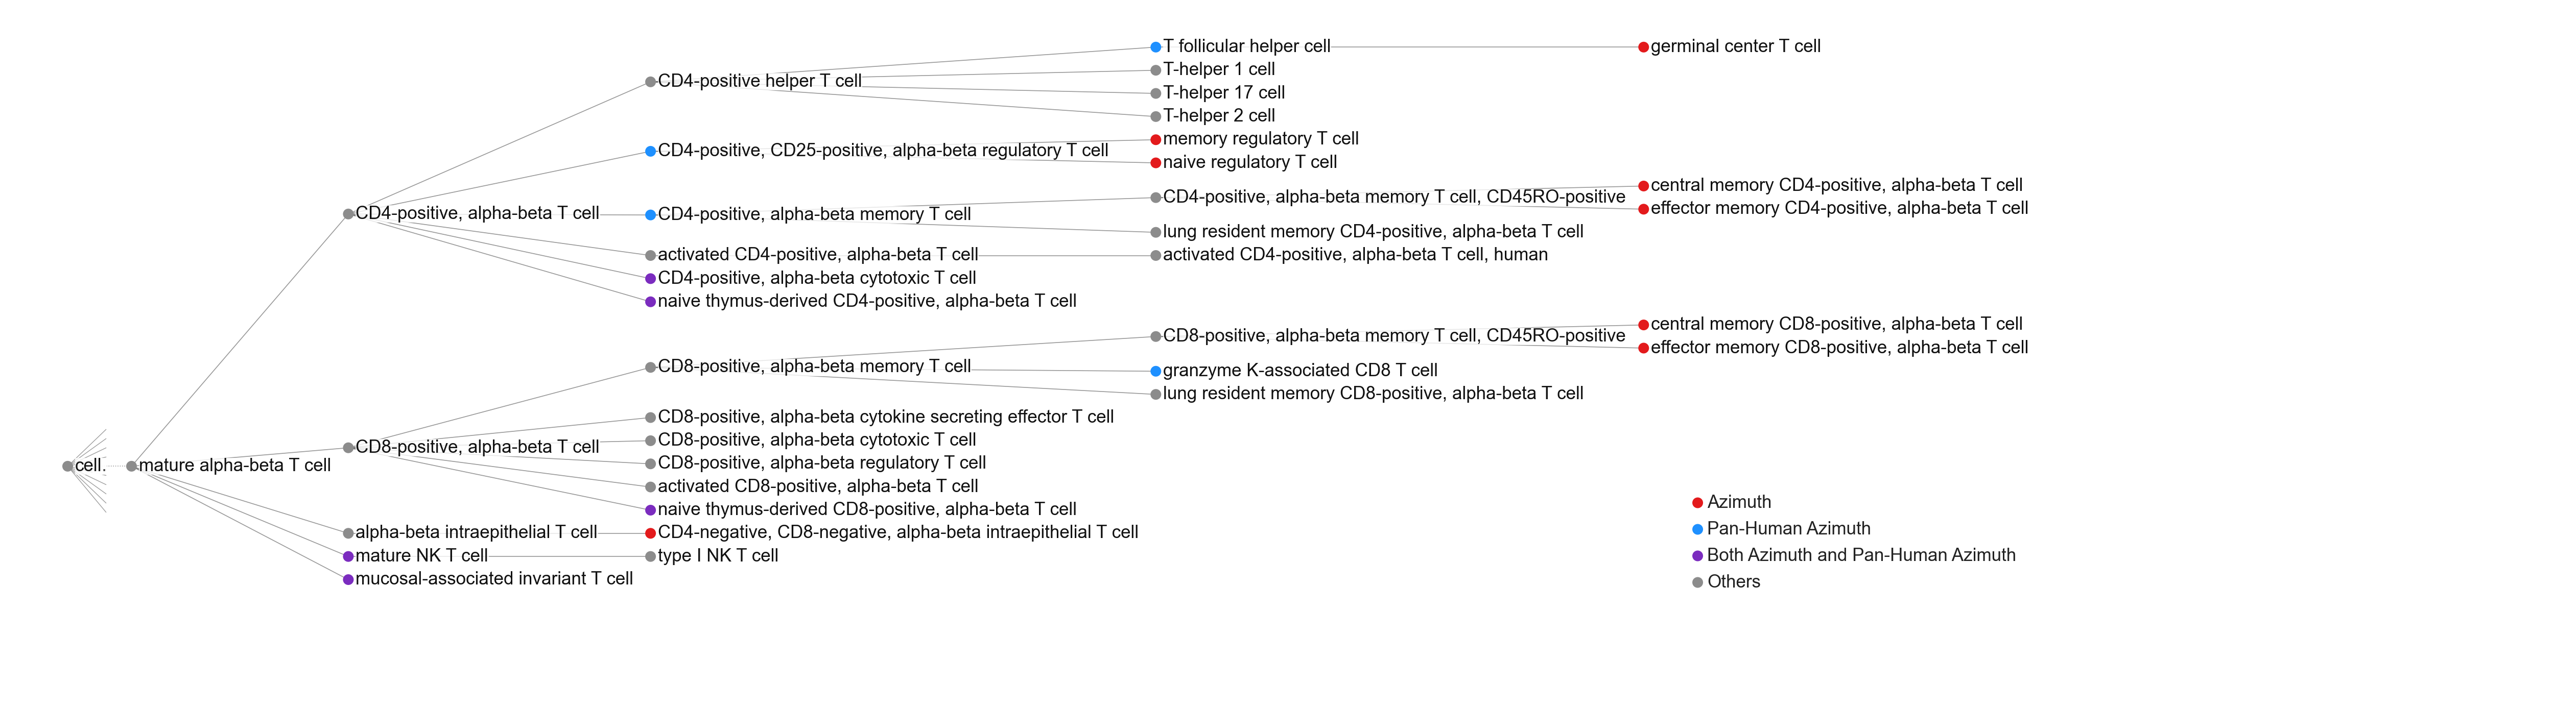

In [3]:
# Step 3: Create tree 1.
SHORTENED_MYOBLAST_CHILD_ID = "CL:0000515"
def create_tree(
    tree_rows,
    *,
    output_stem,
    label_position,
    leaf_step,
    column_dx,
    left_margin,
    label_gap,
):
    node_sources = defaultdict(set)
    node_labels = {}
    parents = defaultdict(set)
    children = defaultdict(set)
    edge_counts = Counter()

    for source_norm, path in tree_rows:
        previous_id = None
        for node_id, node_label in path:
            node_sources[node_id].add(source_norm)
            node_labels[node_id] = node_label

            if previous_id and previous_id != node_id:
                parents[node_id].add(previous_id)
                children[previous_id].add(node_id)
                edge_counts[(previous_id, node_id)] += 1
            previous_id = node_id

    if not node_sources:
        raise ValueError("No nodes were found for this tree.")

    roots = [node for node in node_sources if not parents[node]]
    if not roots:
        roots = [min(node_sources)]

    depth = {}
    queue = deque()
    for root in sorted(roots, key=lambda node: (node_labels.get(node, ""), node)):
        depth[root] = 0
        queue.append(root)

    while queue:
        node = queue.popleft()
        for child in sorted(
            children[node],
            key=lambda candidate: (
                -edge_counts[(node, candidate)],
                node_labels.get(candidate, ""),
                candidate,
            ),
        ):
            candidate_depth = depth[node] + 1
            if child not in depth or candidate_depth < depth[child]:
                depth[child] = candidate_depth
                queue.append(child)

    primary_parent = {}
    for node in node_sources:
        if parents[node]:
            primary_parent[node] = sorted(
                parents[node],
                key=lambda parent: (
                    -edge_counts[(parent, node)],
                    depth.get(parent, 999),
                    node_labels.get(parent, ""),
                    parent,
                ),
            )[0]

    primary_children = defaultdict(list)
    for child, parent in primary_parent.items():
        primary_children[parent].append(child)
    for parent in primary_children:
        primary_children[parent].sort(
            key=lambda child: (
                depth.get(child, 999),
                -len(children[child]),
                node_labels.get(child, ""),
                child,
            )
        )

    y_positions = {}
    cursor = 0.0

    def assign_y(node):
        nonlocal cursor
        node_children = primary_children.get(node, [])
        if not node_children:
            y_positions[node] = cursor
            cursor += leaf_step
            return
        for child in node_children:
            assign_y(child)
        y_positions[node] = sum(y_positions[child] for child in node_children) / len(node_children)

    ordered_roots = sorted(roots, key=lambda node: (node_labels.get(node, ""), node))
    for root in ordered_roots:
        assign_y(root)

    for node in sorted(node_sources, key=lambda node: (depth.get(node, 999), node_labels.get(node, ""), node)):
        if node not in y_positions:
            y_positions[node] = cursor
            cursor += leaf_step

    max_depth = max(depth.values())
    min_y = min(y_positions.values())
    max_y = max(y_positions.values())

    # Leave a compact top margin and reserve a dedicated bottom band for the legend.
    top_margin = 70
    bottom_legend_height = 250
    node_diameter = 21
    # Measure each level's longest rendered label and only reserve the space it needs.
    font_properties = FontProperties(family="Arial", size=LABEL_FONT_SIZE)
    label_width_by_depth = defaultdict(float)
    for node, label in node_labels.items():
        clean_label = label.rstrip("'")
        label_width_points = TextPath((0, 0), clean_label, prop=font_properties).get_extents().width
        label_width_pixels = label_width_points * 120 / 72
        label_width_by_depth[depth.get(node, 0)] = max(
            label_width_by_depth[depth.get(node, 0)], label_width_pixels
        )

    label_clearance = 28
    level_x = {0: left_margin}
    for level in range(1, max_depth + 1):
        previous_level_width = label_width_by_depth[level - 1]
        transition_distance = (
            node_diameter
            + label_gap
            + previous_level_width
            + label_clearance
        )
        # Reserve a compact visible gap for the collapsed early levels.
        if level == 1:
            transition_distance = max(transition_distance, 125)
        level_x[level] = level_x[level - 1] + transition_distance

    # Allocate dedicated space for complete labels and the legend.
    right_label_space = 1_000
    right_legend_space = 800
    # Full-size labels need more vertical separation as well as wider levels.
    row_dy = 8.5 * 1.1 * 1.05 * 1.1 * 1.4
    width = level_x[max_depth] + right_label_space + right_legend_space
    layout_height = max(1.0, max_y - min_y) * row_dy
    height = top_margin + layout_height + bottom_legend_height
    vertical_offset = top_margin

    horizontal_offsets = {SHORTENED_MYOBLAST_CHILD_ID: -column_dx / 2}
    positions = {
        node: (
            level_x[depth.get(node, 0)] + horizontal_offsets.get(node, 0),
            vertical_offset + (y_positions[node] - min_y) * row_dy,
        )
        for node in node_sources
    }

    # Restore the earlier PNG width (60 px at 300 dpi) for the full legend.
    export_width = width + 24
    fig = plt.figure(figsize=(export_width / 120, height / 120), dpi=120)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, export_width)
    ax.set_ylim(height, 0)
    ax.axis("off")

    for parent, child in edge_counts:
        parent_x, parent_y = positions[parent]
        child_x, child_y = positions[child]
        is_primary = primary_parent.get(child) == parent
        is_collapsed_root_connection = (
            parent == DISPLAY_CELL_NODE_ID and child == MATURE_ALPHA_BETA_T_CELL_ID
        )
        ax.plot(
            [parent_x + node_diameter / 2, child_x + node_diameter / 2],
            [parent_y + node_diameter / 2, child_y + node_diameter / 2],
            color="#4A4A4A",
            linewidth=1.0 if is_primary else 0.8,
            linestyle=":" if is_collapsed_root_connection else "-",
            alpha=0.56 if is_primary else 0.22,
            zorder=1,
        )
        if parent == DISPLAY_CELL_NODE_ID and child == MATURE_ALPHA_BETA_T_CELL_ID:
            ax.text(
                (parent_x + child_x + node_diameter) / 2,
                (parent_y + child_y + node_diameter) / 2,
                "...",
                fontsize=LABEL_FONT_SIZE,
                ha="center",
                va="center",
                color="#4A4A4A",
                bbox={"facecolor": "#FFFFFF", "edgecolor": "none", "alpha": 0.9, "pad": 0.1},
                zorder=3,
            )

    # Show the other direct children of cell as unlabeled short stubs.
    if DISPLAY_CELL_NODE_ID in positions:
        cell_x, cell_y = positions[DISPLAY_CELL_NODE_ID]
        stub_count = max(0, CELL_CHILD_COUNT - 1)
        negative_offsets = list(range(-(stub_count // 2), 0))
        positive_offsets = list(range(1, stub_count - len(negative_offsets) + 1))
        for offset_index in negative_offsets + positive_offsets:
            ax.plot(
                [cell_x + node_diameter / 2, cell_x + node_diameter / 2 + 75],
                [cell_y + node_diameter / 2, cell_y + node_diameter / 2 + offset_index * 18],
                color="#4A4A4A",
                linewidth=0.8,
                alpha=0.56,
                zorder=1,
            )

    def display_label(label):
        return label.rstrip("'")

    node_texts = {}
    for node, (x, y) in positions.items():
        # Use the official crosswalk frontier for the two focal colors.
        # Nodes superseded by a more-specific descendant remain gray.
        sources = official_node_sources.get(node, set())
        if FOCAL_SOURCES.issubset(sources):
            fill_color = OVERLAP_NODE_FILL_COLOR
        elif "azimuth" in sources:
            fill_color = AZIMUTH_NODE_FILL_COLOR
        elif "pan-human-azimuth" in sources:
            fill_color = PAN_HUMAN_AZIMUTH_NODE_FILL_COLOR
        else:
            fill_color = OTHER_NODE_FILL_COLOR

        ax.add_patch(
            Circle(
                (x + node_diameter / 2, y + node_diameter / 2),
                radius=node_diameter / 2,
                linewidth=0,
                edgecolor="none",
                facecolor=fill_color,
                zorder=2,
            )
        )

        if label_position == "right":
            text_x, text_y, horizontal, vertical = x + node_diameter + label_gap, y + node_diameter / 2, "left", "center"
        else:
            text_x, text_y, horizontal, vertical = x + node_diameter / 2, y + node_diameter + label_gap, "center", "top"

        node_texts[node] = ax.text(
            text_x,
            text_y,
            display_label(node_labels.get(node, node)),
            fontsize=LABEL_FONT_SIZE,
            color="#111111",
            ha=horizontal,
            va=vertical,
            clip_on=False,
            zorder=3,
            bbox={"facecolor": "#FFFFFF", "edgecolor": "none", "alpha": 0.78, "pad": 0.18},
        )

    # Align all legend nodes in one left column while preserving the requested right edge.
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    alignment_text = node_texts.get(SHORTENED_MYOBLAST_CHILD_ID)
    if alignment_text:
        alignment_bbox = alignment_text.get_window_extent(renderer=renderer)
        legend_right_x = ax.transData.inverted().transform((alignment_bbox.x1, alignment_bbox.y1))[0]
    else:
        legend_right_x = level_x[max_depth] + right_label_space + 220

    legend_items = [
        (AZIMUTH_NODE_FILL_COLOR, "Azimuth"),
        (PAN_HUMAN_AZIMUTH_NODE_FILL_COLOR, "Pan-Human Azimuth"),
        (OVERLAP_NODE_FILL_COLOR, "Both Azimuth and Pan-Human Azimuth"),
        (OTHER_NODE_FILL_COLOR, "Others"),
    ]
    measure_text = ax.text(0, 0, max((label for _, label in legend_items), key=len), fontsize=LABEL_FONT_SIZE)
    fig.canvas.draw()
    measure_bbox = measure_text.get_window_extent(renderer=fig.canvas.get_renderer())
    measure_text.remove()
    max_label_width = ax.transData.inverted().transform((measure_bbox.x1, measure_bbox.y1))[0] - ax.transData.inverted().transform((measure_bbox.x0, measure_bbox.y0))[0]
    # Shift the legend left slightly without changing the tree layout.
    # Keep the legend in the latest, further-left position.
    # Shift the legend a little farther left than the preceding version.
    # Shift the legend another 80 canvas units left.
    # Shift the legend another 80 canvas units left.
    legend_text_left_x = legend_right_x - max_label_width - 480
    legend_circle_x = legend_text_left_x - 8 - node_diameter / 2

    # The dedicated lower band keeps the legend clear of the tree and its labels.
    legend_y = height - bottom_legend_height - 140
    for color, label in legend_items:
        ax.add_patch(
            Circle(
                (legend_circle_x, legend_y),
                radius=node_diameter / 2,
                linewidth=0,
                edgecolor="none",
                facecolor=color,
                zorder=2,
            )
        )
        ax.text(
            legend_text_left_x,
            legend_y,
            label,
            fontsize=LABEL_FONT_SIZE,
            ha="left",
            va="center",
            color="#222222",
            zorder=3,
        )
        legend_y += 52


    png_path = OUTPUT_DIR / f"{output_stem}.png"
    svg_path = OUTPUT_DIR / f"{output_stem}.svg"
    # Export the fixed original-width canvas without expanding it around text.
    fig.savefig(png_path, dpi=300)
    fig.savefig(svg_path)
    plt.show()
    plt.close(fig)

create_tree(
    tree1_rows,
    output_stem="ctann-v10-official-hierarchy-frontier-fixed-cell-child-stubs-mature-alpha-beta-t-cell-branch-dotted-legend-bottom-shifted-up130",
    label_position="right",
    leaf_step=3.0,
    column_dx=900,
    left_margin=110,
    label_gap=4,
)
